# O susto do Tesouro IPCA+ longo: marcação a mercado na prática

Gabriel Pires · [@gabrielp.pires](https://instagram.com/gabrielp.pires) · 09/2026

---

Em 2026, quem tinha **Tesouro IPCA+ 2050** viu o preço do título cair **12,6%** em três meses e meio. O governo não deu calote e a inflação não sumiu: bastou a taxa de mercado subir 76 bp. Este notebook mostra, conta por conta, por que isso acontece e por que esse "susto" só vira prejuízo para quem vende antes do vencimento.

**Dados:** `NTNB_Principal_2026.xls`, preços e taxas diários do Tesouro Direto, de 02/01/2026 a 27/08/2026, uma aba por vencimento.

## 1. Bibliotecas e parâmetros

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bizdays import Calendar          # pip install bizdays (calendário ANBIMA embutido)

ARQUIVO = "NTNB_Principal_2026.xls"   # na mesma pasta do notebook; ler .xls exige pip install xlrd

cal = Calendar.load("ANBIMA")

# vencimentos usados (a aba de 15/08/2026 fica de fora: venceu dentro da janela)
VENCIMENTOS = {
    "2029": ("NTN-B Princ 150529", "2029-05-15"),
    "2032": ("NTN-B Princ 150832", "2032-08-15"),
    "2035": ("NTN-B Princ 150535", "2035-05-15"),
    "2040": ("NTN-B Princ 150840", "2040-08-15"),
    "2045": ("NTN-B Princ 150545", "2045-05-15"),
    "2050": ("NTN-B Princ 150850", "2050-08-15"),
}

BG, WHITE, GREY, CYAN, AMBER, PINK = "#07080D", "#E6E6E9", "#6C6D72", "#4AADD6", "#E8A13A", "#DE235B"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": GREY, "axes.labelcolor": GREY, "xtick.color": GREY, "ytick.color": GREY,
    "text.color": WHITE, "axes.spines.top": False, "axes.spines.right": False,
    "font.family": "DejaVu Sans Mono", "figure.figsize": (9, 5), "figure.dpi": 110,
})

## 2. Como funciona o Tesouro IPCA+

O **Tesouro IPCA+** (sem juros semestrais) é a **NTN-B Principal**. Ele é um título *zero-cupom*: não paga nada no meio do caminho e entrega tudo no vencimento.

**O que você recebe no vencimento** é o **VNA** (Valor Nominal Atualizado): R$ 1.000 na data-base (15/07/2000) corrigidos pelo IPCA acumulado até hoje. Ou seja, o valor de face cresce com a inflação.

**O preço de hoje** é esse valor trazido a valor presente pela taxa real de mercado:

$$
PU_t = \frac{VNA_t}{(1+\text{taxa}_t)^{du_t/252}}
$$

- $VNA_t$: R$ 1.000 corrigidos pelo IPCA até $t$ (com projeção de IPCA para o mês corrente);
- $\text{taxa}_t$: taxa **real** anual, base 252, que o mercado exige **hoje**;
- $du_t$: dias úteis até o vencimento.

**A consequência central.** Quem compra trava a taxa **contratada** para levar até o vencimento. O preço diário, porém, é recalculado com a taxa **do dia**. Se a taxa de mercado sobe, o denominador cresce e o PU cai. Isso é **marcação a mercado**.

**Compra × venda no Tesouro Direto.** Cada dia tem duas taxas:

- **Taxa de Compra**: a taxa que o investidor consegue ao comprar. É menor, e o PU é maior.
- **Taxa de Venda**: a taxa usada quando o investidor vende de volta ao Tesouro. É maior, e o PU é menor.

Para medir quanto vale **hoje** a posição de quem já tem o título, o certo é o **PU de Venda**, que é o valor de resgate.

## 3. Leitura dos arquivos

Cada aba tem duas linhas de cabeçalho: a primeira traz o vencimento, a segunda o nome das colunas. As taxas vêm em **decimal** (0,0705 = 7,05% a.a.) e as datas no formato dd/mm/aaaa.

In [2]:
def ler_titulo(aba, venc):
    d = pd.read_excel(ARQUIVO, sheet_name=aba, header=1)
    d.columns = ["dia", "taxa_compra", "taxa_venda", "pu_compra", "pu_venda", "pu_base"]
    d["dia"] = pd.to_datetime(d["dia"], format="%d/%m/%Y")
    v = cal.adjust_next(pd.Timestamp(venc).date())
    d["du"] = [cal.bizdays(x.date(), v) for x in d["dia"]]
    return d

titulos = {k: ler_titulo(aba, venc) for k, (aba, venc) in VENCIMENTOS.items()}
b50 = titulos["2050"]
print(f"{len(b50)} dias úteis: {b50.dia.min():%d/%m/%Y} a {b50.dia.max():%d/%m/%Y}")
b50.head()

164 dias úteis: 02/01/2026 a 27/08/2026


,dia,taxa_compra,taxa_venda,pu_compra,pu_venda,pu_base,du
0,2026-01-02,0.0693,0.0705,889.71,865.12,865.12,6164
1,2026-01-05,0.0694,0.0706,888.01,863.66,863.66,6163
2,2026-01-06,0.0700,0.0712,876.25,852.24,852.24,6162
3,2026-01-07,0.0705,0.0717,866.63,842.89,842.89,6161
4,2026-01-08,0.0702,0.0714,872.91,849.00,849.00,6160


## 4. Checagem: o VNA implícito

Antes de qualquer análise, vale conferir se entendemos a fórmula. Invertendo a equação do PU:

$$
VNA_t = PU_t \times (1+\text{taxa}_t)^{du_t/252}
$$

Se a convenção de dias úteis estiver certa, o VNA implícito precisa ser uma série **suave e crescente**: ele só anda com o IPCA, não com o humor do mercado. Os títulos também precisam concordar entre si, porque todas as NTN-B têm o **mesmo VNA** na mesma data.

Se aparecer um degrau ou uma diferença grande entre vencimentos, a contagem de $du$ está errada.

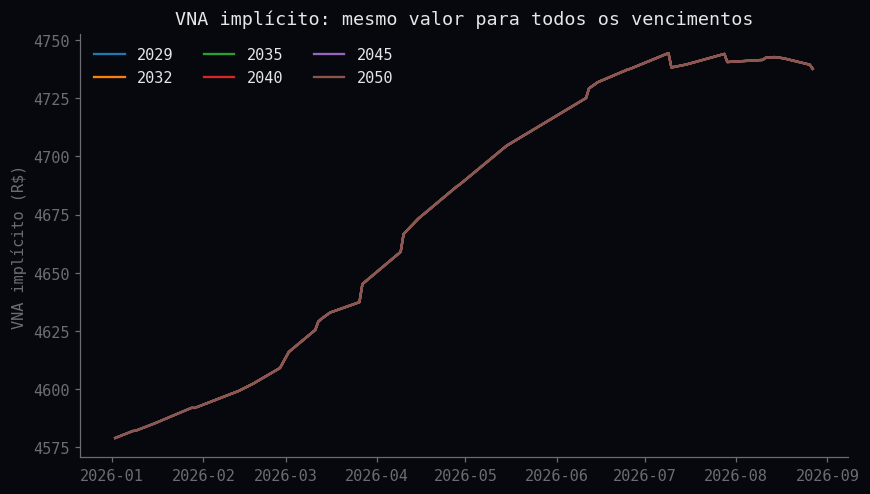

VNA implícito (2050): 4579.05 → 4737.55  (3.46% no período)
maior variação diária absoluta: 0.168%


In [3]:
fig, ax = plt.subplots()
for k, d in titulos.items():
    vna = d["pu_venda"] * (1 + d["taxa_venda"]) ** (d["du"] / 252)
    titulos[k]["vna_impl"] = vna
    ax.plot(d["dia"], vna, lw=1.5, label=k)
ax.set(ylabel="VNA implícito (R$)", title="VNA implícito: mesmo valor para todos os vencimentos")
ax.legend(frameon=False, ncol=3)
plt.show()

v = b50["vna_impl"]
print(f"VNA implícito (2050): {v.iloc[0]:.2f} → {v.iloc[-1]:.2f}  ({(v.iloc[-1]/v.iloc[0]-1)*100:.2f}% no período)")
print(f"maior variação diária absoluta: {v.pct_change().abs().max()*100:.3f}%")

O VNA sobe de forma suave (é o IPCA acumulado) e as seis curvas se sobrepõem, então a fórmula e a contagem de dias úteis estão corretas. Toda a volatilidade do PU vem, portanto, **da taxa**.

> Pequenas diferenças de centavos entre os vencimentos vêm de arredondamento/truncamento do PU e da taxa divulgados.

## 5. Sensibilidade à taxa: duration e convexidade

**Variação exata.** Se a taxa sai de $y$ para $y+\Delta y$ no mesmo dia (VNA e $du$ fixos), o VNA se cancela e sobra:

$$
\frac{PU_{novo}}{PU} - 1 = \left(\frac{1+y}{1+y+\Delta y}\right)^{\tau} - 1, \qquad \tau = du/252
$$

**Aproximação linear.** A **duration modificada** diz quanto o PU varia, em %, para cada 1 p.p. de taxa:

$$
\frac{\Delta PU}{PU} \approx -D_{mod}\,\Delta y, \qquad D_{mod} = \frac{\tau}{1+y}
$$

Num título zero-cupom, a duration de Macaulay é o próprio prazo $\tau$. Por isso o IPCA+ 2050, com cerca de 24 anos, é tão sensível: $D_{mod} \approx 22$, ou seja, cerca de 22% de queda para cada 1 p.p. de alta na taxa.

**Convexidade.** A aproximação linear exagera a queda quando a taxa sobe e subestima o ganho quando a taxa cai. A diferença é a **convexidade**, que cresce com $\tau^2$ e por isso é relevante nos títulos longos.

In [4]:
REF = b50["dia"].iloc[-1]

def choque_exato(y, tau, dy):
    return (((1 + y) / (1 + y + dy)) ** tau - 1) * 100

linhas = []
for k, d in titulos.items():
    y, tau = d["taxa_venda"].iloc[-1], d["du"].iloc[-1] / 252
    linhas.append({"titulo": f"IPCA+ {k}", "taxa_%": y*100, "prazo_anos": tau, "D_mod": tau/(1+y),
                   "+0,5pp_exato_%": choque_exato(y, tau, 0.005),
                   "+1pp_exato_%": choque_exato(y, tau, 0.01),
                   "+1pp_linear_%": -tau/(1+y)*1.0})
sens = pd.DataFrame(linhas)
print(f"Taxas de {REF:%d/%m/%Y}")
sens.round(2)

Taxas de 27/08/2026


,titulo,taxa_%,prazo_anos,D_mod,"+0,5pp_exato_%",+1pp_exato_%,+1pp_linear_%
0,IPCA+ 2029,8.17,2.68,2.48,-1.23,-2.44,-2.48
1,IPCA+ 2032,8.12,5.93,5.48,-2.70,-5.31,-5.48
2,IPCA+ 2035,7.93,8.65,8.02,-3.92,-7.67,-8.02
3,IPCA+ 2040,7.58,13.88,12.91,-6.24,-12.06,-12.91
4,IPCA+ 2045,7.44,18.60,17.31,-8.27,-15.83,-17.31
5,IPCA+ 2050,7.38,23.81,22.18,-10.47,-19.81,-22.18


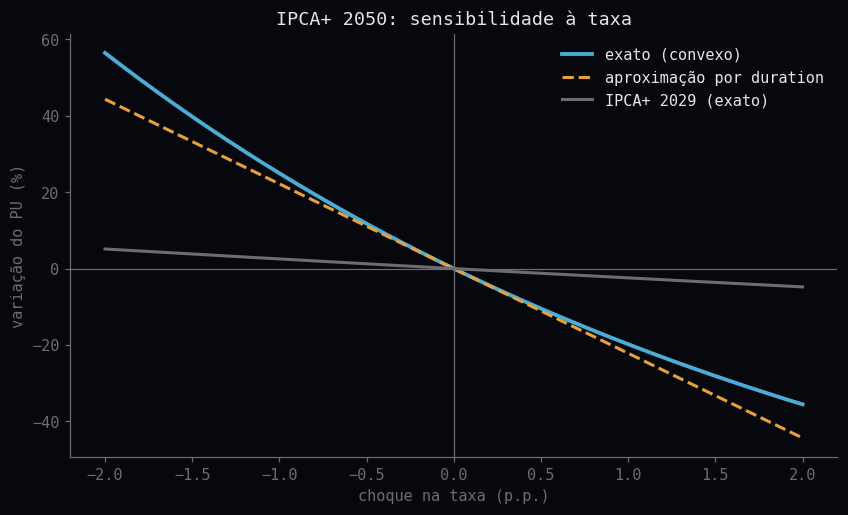

In [5]:
y50, tau50 = b50["taxa_venda"].iloc[-1], b50["du"].iloc[-1] / 252
dy = np.linspace(-0.02, 0.02, 200)

fig, ax = plt.subplots()
ax.plot(dy*100, choque_exato(y50, tau50, dy), color=CYAN, lw=2.5, label="exato (convexo)")
ax.plot(dy*100, -tau50/(1+y50)*dy*100, ls="--", color=AMBER, lw=2, label="aproximação por duration")
y29, tau29 = titulos["2029"]["taxa_venda"].iloc[-1], titulos["2029"]["du"].iloc[-1] / 252
ax.plot(dy*100, choque_exato(y29, tau29, dy), color=GREY, lw=2, label="IPCA+ 2029 (exato)")
ax.axhline(0, color=GREY, lw=0.8); ax.axvline(0, color=GREY, lw=0.8)
ax.set(xlabel="choque na taxa (p.p.)", ylabel="variação do PU (%)", title="IPCA+ 2050: sensibilidade à taxa")
ax.legend(frameon=False)
plt.show()

## 6. A trajetória real do IPCA+ 2050 em 2026

Para achar o "susto", medimos o **drawdown**: a queda do PU em relação ao maior valor atingido **até aquele dia**.

$$
DD_t = \frac{PU_t}{\max_{s\le t} PU_s} - 1
$$

O **drawdown máximo** é o pior valor dessa série. O **topo** é o dia do máximo anterior a esse pior ponto, e o **fundo** é o próprio pior ponto.

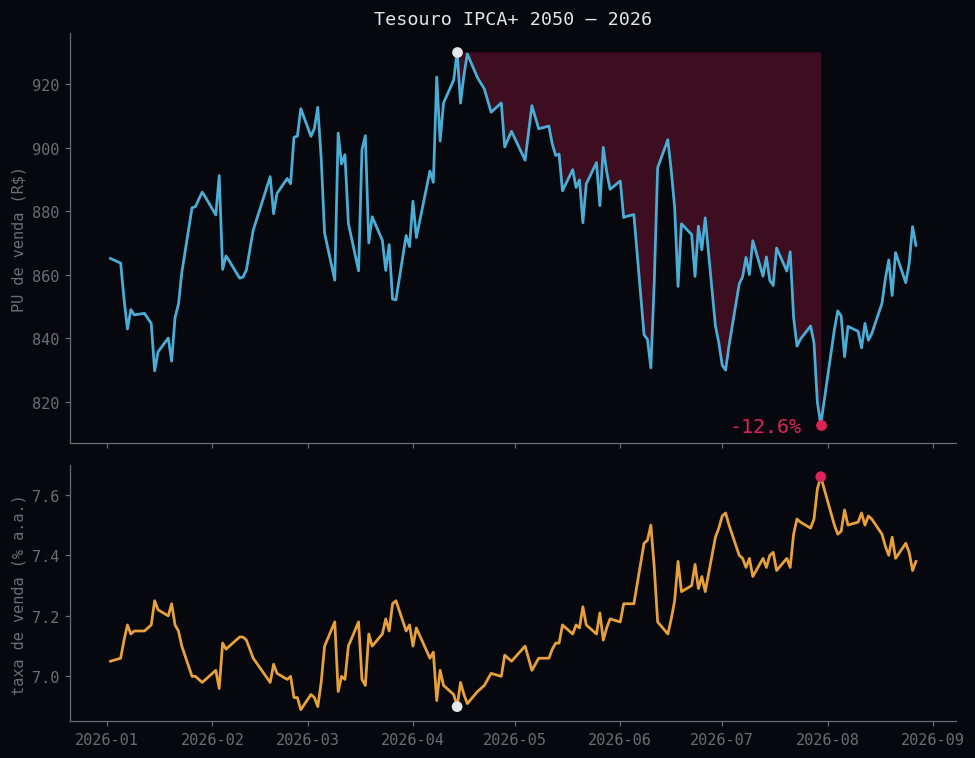

Topo : 14/04/2026  PU R$ 930.30  taxa 6.90%
Fundo: 30/07/2026  PU R$ 812.75  taxa 7.66%
Taxa: +76 bp  |  PU: -12.64%


In [6]:
def drawdown_max(d, col="pu_venda"):
    dd = d[col] / d[col].cummax() - 1
    i_fundo = dd.idxmin()
    i_topo = d[col].iloc[:i_fundo + 1].idxmax()
    return dd.min() * 100, i_topo, i_fundo, dd

dd50, i_topo, i_fundo, serie_dd = drawdown_max(b50)
topo, fundo = b50.loc[i_topo], b50.loc[i_fundo]

fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
a1.plot(b50.dia, b50.pu_venda, color=CYAN, lw=1.8)
a1.fill_between(b50.dia[i_topo:i_fundo+1], b50.pu_venda[i_topo:i_fundo+1], topo.pu_venda, color=PINK, alpha=0.25, lw=0)
a1.scatter([topo.dia], [topo.pu_venda], color=WHITE, zorder=3)
a1.scatter([fundo.dia], [fundo.pu_venda], color=PINK, zorder=3)
a1.annotate(f"{dd50:.1f}%", (fundo.dia, fundo.pu_venda), xytext=(-60, -5), textcoords="offset points", color=PINK, fontsize=13)
a1.set(ylabel="PU de venda (R$)", title="Tesouro IPCA+ 2050 — 2026")
a2.plot(b50.dia, b50.taxa_venda*100, color=AMBER, lw=1.8)
a2.scatter([topo.dia, fundo.dia], [topo.taxa_venda*100, fundo.taxa_venda*100], color=[WHITE, PINK], zorder=3)
a2.set(ylabel="taxa de venda (% a.a.)")
plt.tight_layout(); plt.show()

print(f"Topo : {topo.dia:%d/%m/%Y}  PU R$ {topo.pu_venda:,.2f}  taxa {topo.taxa_venda*100:.2f}%")
print(f"Fundo: {fundo.dia:%d/%m/%Y}  PU R$ {fundo.pu_venda:,.2f}  taxa {fundo.taxa_venda*100:.2f}%")
print(f"Taxa: +{(fundo.taxa_venda-topo.taxa_venda)*1e4:.0f} bp  |  PU: {dd50:.2f}%")

## 7. Decompondo a queda: taxa × inflação × tempo

Entre o topo e o fundo, três coisas mudaram ao mesmo tempo: a **taxa** subiu, o **VNA** cresceu com o IPCA e o **prazo** encurtou. Tomando o log da fórmula do PU:

$$
\ln PU = \ln VNA - \frac{du}{252}\ln(1+y)
$$

A variação entre as datas 1 e 2 se decompõe **exatamente** em três termos:

$$
\Delta \ln PU = \underbrace{\ln\frac{VNA_2}{VNA_1}}_{\text{inflação}}
\;-\; \underbrace{\frac{du_2}{252}\left[\ln(1+y_2)-\ln(1+y_1)\right]}_{\text{efeito taxa}}
\;+\; \underbrace{\frac{du_1-du_2}{252}\ln(1+y_1)}_{\text{passagem do tempo (carrego)}}
$$

Assim, os −12,6% do vídeo são o **resultado líquido**: o choque de taxa foi ainda maior, e parte dele foi amortecida pela inflação e pelo carrego.

In [7]:
t1, t2 = topo, fundo
inflacao = np.log(t2.vna_impl / t1.vna_impl)
efeito_taxa = -(t2.du/252) * (np.log(1 + t2.taxa_venda) - np.log(1 + t1.taxa_venda))
carrego = ((t1.du - t2.du)/252) * np.log(1 + t1.taxa_venda)
total = np.log(t2.pu_venda / t1.pu_venda)

dec = pd.DataFrame({
    "componente": ["inflação (VNA)", "efeito taxa", "carrego (tempo)", "soma", "Δ ln PU observado"],
    "log_%": np.array([inflacao, efeito_taxa, carrego, inflacao+efeito_taxa+carrego, total]) * 100,
})
dec["em_%_simples"] = (np.exp(dec["log_%"]/100) - 1) * 100
dec.round(2)

,componente,log_%,em_%_simples
0,inflação (VNA),1.46,1.47
1,efeito taxa,-16.93,-15.57
2,carrego (tempo),1.96,1.98
3,soma,-13.51,-12.64
4,Δ ln PU observado,-13.51,-12.64


## 8. Quanto mais longo, maior o susto

Aplicamos o mesmo drawdown máximo a todos os vencimentos. Todos enfrentaram o **mesmo movimento de juros** em 2026, mas com durations muito diferentes. A duration funciona como uma **alavanca**: amplifica o mesmo choque de taxa.

> Os topos e fundos não caem necessariamente nos mesmos dias para todos os vencimentos, porque a curva não se move de forma paralela.

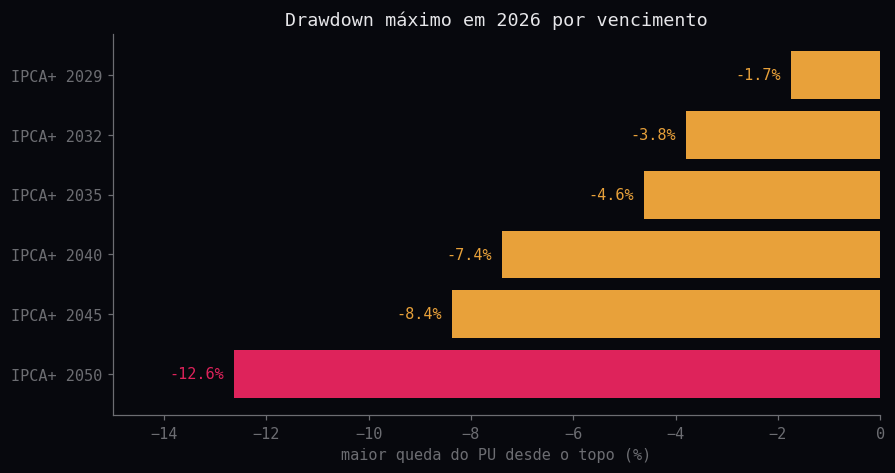

,titulo,prazo_anos_hoje,topo,fundo,Δtaxa_bp,drawdown_max_%
0,IPCA+ 2029,2.68,2026-05-27,2026-06-10,84.0,-1.74
1,IPCA+ 2032,5.93,2026-04-22,2026-06-22,110.0,-3.79
2,IPCA+ 2035,8.65,2026-04-22,2026-06-10,80.0,-4.61
3,IPCA+ 2040,13.88,2026-04-17,2026-07-02,80.0,-7.39
4,IPCA+ 2045,18.60,2026-04-14,2026-06-10,62.0,-8.37
5,IPCA+ 2050,23.81,2026-04-14,2026-07-30,76.0,-12.64


In [8]:
tab = []
for k, d in titulos.items():
    ddm, it, i_f, _ = drawdown_max(d)
    tab.append({"titulo": f"IPCA+ {k}", "prazo_anos_hoje": d.du.iloc[-1]/252,
                "topo": d.dia[it].date(), "fundo": d.dia[i_f].date(),
                "Δtaxa_bp": (d.taxa_venda[i_f]-d.taxa_venda[it])*1e4, "drawdown_max_%": ddm})
tab = pd.DataFrame(tab)

fig, ax = plt.subplots(figsize=(9, 4.5))
cores = [PINK if t.endswith("2050") else AMBER for t in tab.titulo]
ax.barh(tab.titulo, tab["drawdown_max_%"], color=cores)
for i, v in enumerate(tab["drawdown_max_%"]):
    ax.text(v - 0.2, i, f"{v:.1f}%", va="center", ha="right", color=cores[i])
ax.invert_yaxis(); ax.set_xlim(-15, 0)
ax.set(xlabel="maior queda do PU desde o topo (%)", title="Drawdown máximo em 2026 por vencimento")
plt.show()
tab.round(2)

## 9. Vender no fundo × segurar até o vencimento

**Quem comprou no topo e vendeu no fundo** realizou a perda, e ela não volta. Somando o spread de compra e venda, o resultado fica ainda pior que os −12,6% do PU de venda: veja o cálculo abaixo.

**Quem comprou no topo e segurou** continua com o contrato original: vai receber o VNA em 2050, que é **IPCA + a taxa contratada** ao ano, qualquer que seja o caminho do PU até lá. No vencimento $du = 0$, então $PU = VNA$ e a marcação a mercado desaparece.

O gráfico abaixo é **ilustrativo**. Ele simula uma taxa de mercado oscilando em torno da taxa contratada, com o VNA normalizado em 100%, para mostrar que:

- a linha tracejada (PU/VNA à taxa contratada) sobe de forma suave até 100%;
- a linha azul (PU/VNA à taxa de mercado) oscila, mas **converge para o mesmo ponto** no vencimento.

> Nota: comprar no Tesouro Direto acontece pela **taxa de compra**, um pouco menor que a de venda. A taxa efetivamente contratada no topo seria a de compra daquele dia.

Comprou em 14/04/2026: taxa de compra 6.78% | PU de compra R$ 956.44
Vendeu  em 30/07/2026: PU de venda R$ 812.75
Resultado realizado: -15.02% (antes de IR e custódia)
Se segurar até 2050: IPCA + 6.78% a.a. (antes de IR e custódia)


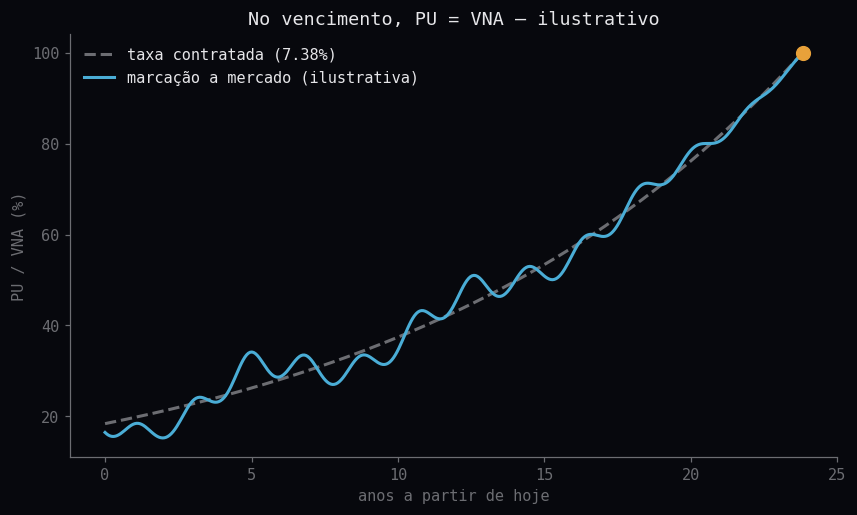

In [9]:
print(f"Comprou em {topo.dia:%d/%m/%Y}: taxa de compra {topo.taxa_compra*100:.2f}% | PU de compra R$ {topo.pu_compra:,.2f}")
print(f"Vendeu  em {fundo.dia:%d/%m/%Y}: PU de venda R$ {fundo.pu_venda:,.2f}")
print(f"Resultado realizado: {(fundo.pu_venda/topo.pu_compra-1)*100:.2f}% (antes de IR e custódia)")
print(f"Se segurar até 2050: IPCA + {topo.taxa_compra*100:.2f}% a.a. (antes de IR e custódia)")

# trajetória ilustrativa
T = tau50; ts = np.linspace(0, T, 400); yc = y50
y_mkt = yc + 0.012*np.sin(ts*0.9)*np.exp(-0.05*ts) + 0.006*np.sin(ts*3.3 + 1)
fig, ax = plt.subplots()
ax.plot(ts, 100/(1+yc)**(T-ts), ls="--", color=GREY, lw=2, label=f"taxa contratada ({yc*100:.2f}%)")
ax.plot(ts, 100/(1+y_mkt)**(T-ts), color=CYAN, lw=2, label="marcação a mercado (ilustrativa)")
ax.scatter([T], [100], color=AMBER, s=80, zorder=3)
ax.set(xlabel="anos a partir de hoje", ylabel="PU / VNA (%)", title="No vencimento, PU = VNA — ilustrativo")
ax.legend(frameon=False)
plt.show()

---
Gabriel Pires · [@gabrielp.pires](https://instagram.com/gabrielp.pires)

© 2026 · Conteúdo educacional. Não é recomendação de investimento.